# Error Analysis — Frozen ResNet18 + U-Net

**Цель:** выяснить, на каких изображениях модель ошибается сильнее, насколько L1 отражает визуальное качество колоризации и превосходит ли модель простое предсказание нулевых цветовых каналов (grayscale baseline).

Анализируем модель с замороженным энкодером ResNet18 на **validation split**. Метрика — средняя абсолютная ошибка по двум **нормализованным** каналам `ab` для каждого изображения.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.color import lab2rgb

from image_colorization.resnet_unet import ResNetUNet
from image_colorization.dataloaders import create_dataloaders
from image_colorization.color_utils import denormalize_lab

## 2. Validation Data and Model

In [2]:
images_dir = Path('../VOCdevkit/VOC2012/JPEGImages')
train_path = Path("../data/splits/train.txt")
val_path = Path("../data/splits/val.txt")

train_loader, val_loader = create_dataloaders(images_dir=images_dir,
                                              train_path=train_path,
                                              val_path=val_path)

In [3]:
best_path = Path("../checkpoints/resnet18_unet_frozen_encoder_best.pt")

best_checkpoint = torch.load(best_path, map_location="cpu", weights_only=True)
model = ResNetUNet().to("cpu")
model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

ResNetUNet(
  (normalize): Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1)

## 3. Per-image L1 Errors

Для каждого изображения вычисляем:

- `L1_model` — среднюю абсолютную ошибку предсказанных каналов `ab`;
- `L1_gray` — ошибку простого baseline, у которого `a = b = 0`;
- `delta_L1 = L1_gray − L1_model` — выигрыш модели над grayscale baseline.


In [4]:
losses = []
gray_losses = []

model.eval()
with torch.no_grad():
    for L, ab in val_loader:
        pred = model(L)

        model_errors = (pred - ab).abs().mean(dim=(1, 2, 3))
        gray_errors = ab.abs().mean(dim=(1, 2, 3))  # grayscale: predicted ab == 0

        losses.extend(model_errors.cpu().tolist())
        gray_losses.extend(gray_errors.cpu().tolist())

delta_losses = np.asarray(gray_losses) - np.asarray(losses)

In [6]:
print(f"Validation images: {len(losses)}")
print(f"Model mean L1:     {np.mean(losses):.4f}")
print(f"Model median L1:   {np.median(losses):.4f}")
print(f"Model 90th pct L1: {np.percentile(losses, 90):.4f}")

Validation images: 2569
Model mean L1:     0.0597
Model median L1:   0.0531
Model 90th pct L1: 0.1007


### 3.1. Error Distribution

Гистограмма ниже показывает разброс `L1_model` по изображениям

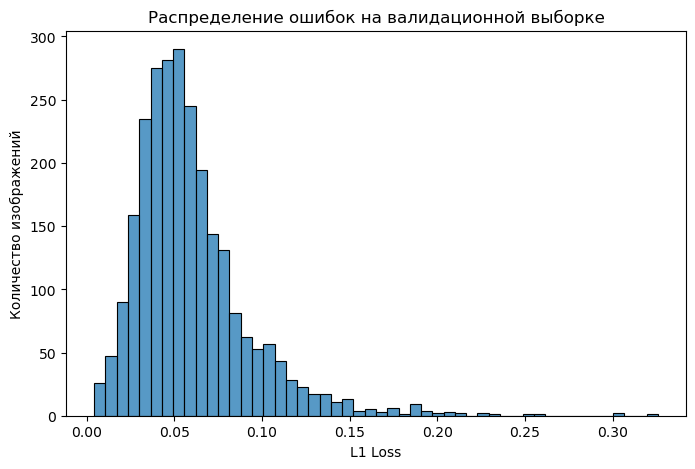

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(losses, bins=50, ax=ax)
ax.set_title("Распределение ошибок на валидационной выборке")
ax.set_xlabel("L1 Loss")
ax.set_ylabel("Количество изображений")
plt.show()

## 4. Qualitative Error Analysis

Рассмотрим по пять **первых подходящих по порогу** изображений из каждой группы:

- **Low L1:** `L1 < 0.02` — проверим, не объясняется ли малая ошибка низкой насыщенностью самого изображения.
- **Typical L1:** `0.04 ≤ L1 ≤ 0.06` — оценим характерные предсказания.
- **High L1:** `L1 > 0.18` — посмотрим, какие цвета и сцены вызывают наибольшие ошибки.

В каждом сравнении показаны: оригинал, входное изображение (канал `L`) и результат модели.

In [8]:
low_idx = [i for i, loss in enumerate(losses) if loss < 0.02][:5]
typical_idx = [i for i, loss in enumerate(losses) if 0.04 <= loss <= 0.06][:5]
high_idx = [i for i, loss in enumerate(losses) if loss > 0.18][:5]

### 4.1. Visualization

In [9]:
def get_imgs(idx_array):
    fig, axes = plt.subplots(5, 3, figsize=(8, 10))
    model.eval()
    for i in range(5):
        L, ab = val_loader.dataset[idx_array[i]]

        L_np = L[0].numpy()
        orig_rgb = lab2rgb(denormalize_lab(L_np, ab.permute(1, 2, 0).numpy()))

        with torch.no_grad():
            pred_ab = model(L[None])[0].permute(1, 2, 0).cpu().numpy()

        pred_rgb = lab2rgb(denormalize_lab(L_np, pred_ab))

        axes[i, 0].imshow(orig_rgb)
        axes[i, 1].imshow(L_np, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].imshow(pred_rgb)

        for ax in axes[i]:
            ax.axis("off")

    axes[0, 0].set_title("Original RGB")
    axes[0, 1].set_title("Grayscale")
    axes[0, 2].set_title("Predicted RGB")

    plt.tight_layout()
    plt.show()

### 4.2. Low L1

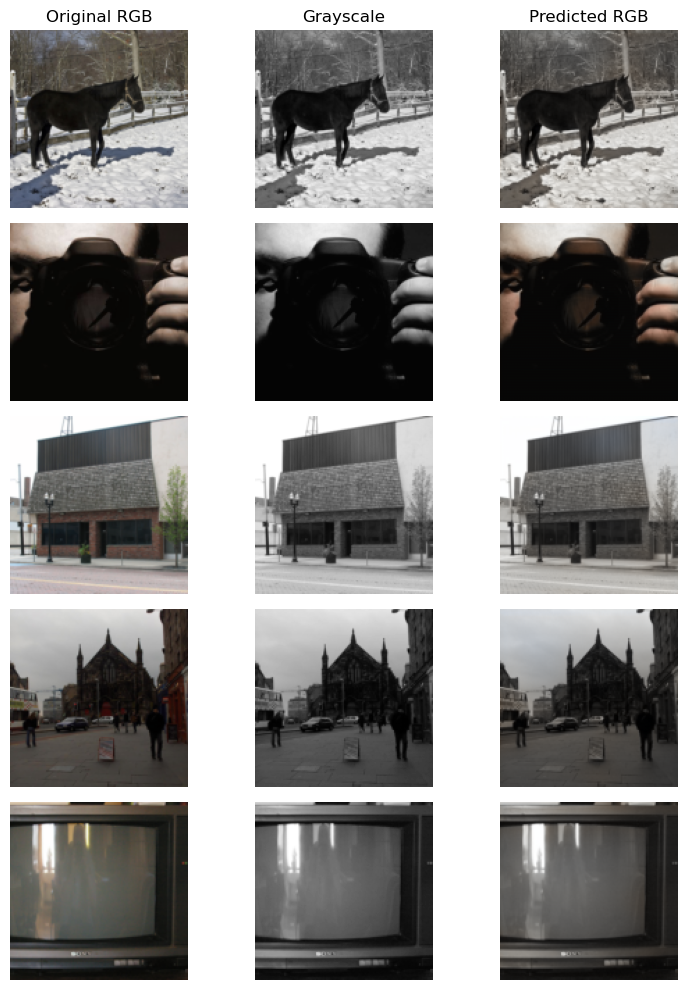

In [10]:
get_imgs(low_idx)

### 4.3. Typical L1

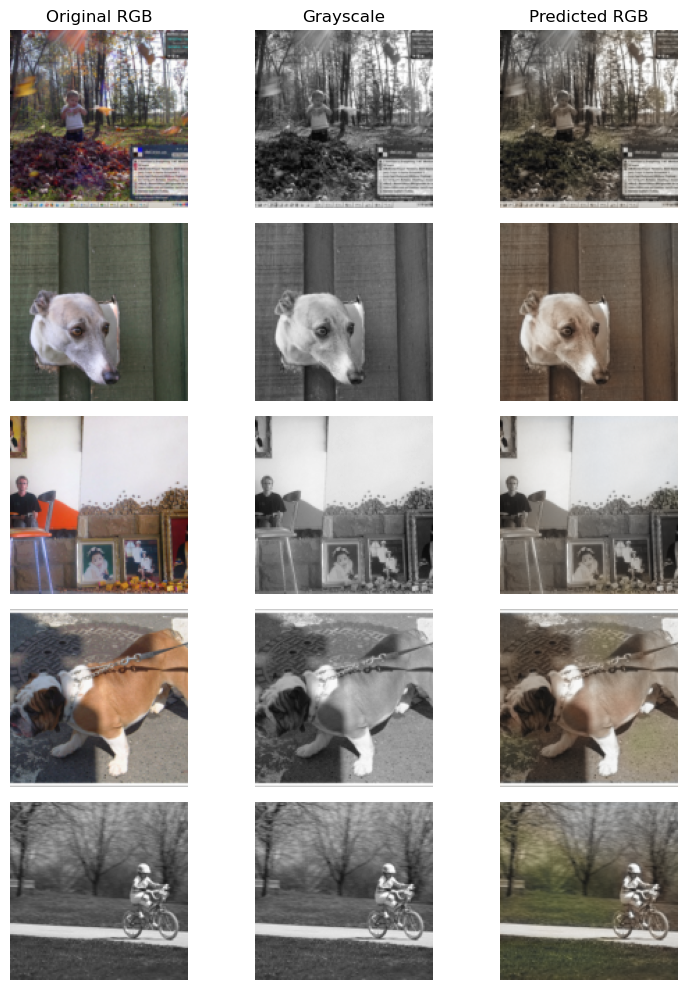

In [11]:
get_imgs(typical_idx)

### 4.4. High L1

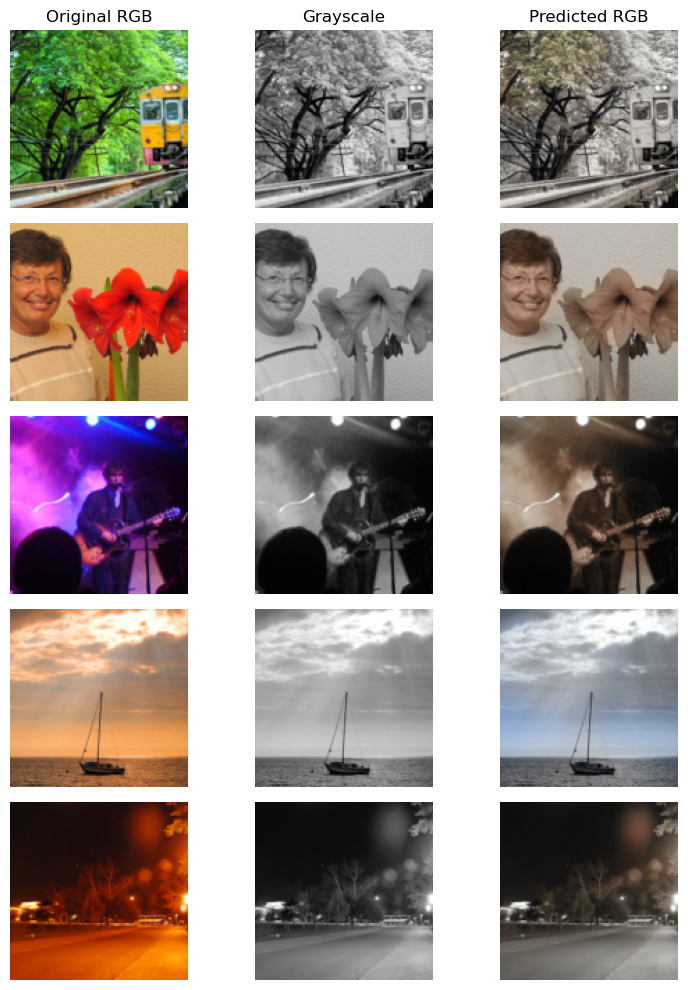

In [12]:
get_imgs(high_idx)

## 5. Comparison with Grayscale Baseline

Для изображения с настоящими цветными каналами `ab` предсказание grayscale baseline равно нулю по обоим каналам. Поэтому:

$$
\Delta L1 = L1_{\mathrm{gray}} - L1_{\mathrm{model}}
$$

- `ΔL1 > 0` — модель точнее grayscale baseline по L1;
- `ΔL1 < 0` — grayscale baseline точнее;
- `ΔL1 = 0` — результаты равны.

Сравниваем **ошибки на одних и тех же изображениях**, а не просто средние значения по разным выборкам.

In [13]:
print(f"Mean L1, model:      {np.mean(losses):.4f}")
print(f"Mean L1, grayscale:  {np.mean(gray_losses):.4f}")
print(f"Mean delta L1:       {np.mean(delta_losses):+.4f}")
print(f"Median delta L1:     {np.median(delta_losses):+.4f}")
print(f"Model better:        {(delta_losses > 0).mean():.1%} of images")
print(f"Grayscale better:    {(delta_losses < 0).mean():.1%} of images")

Mean L1, model:      0.0597
Mean L1, grayscale:  0.0689
Mean delta L1:       +0.0092
Median delta L1:     +0.0065
Model better:        71.4% of images
Grayscale better:    28.6% of images


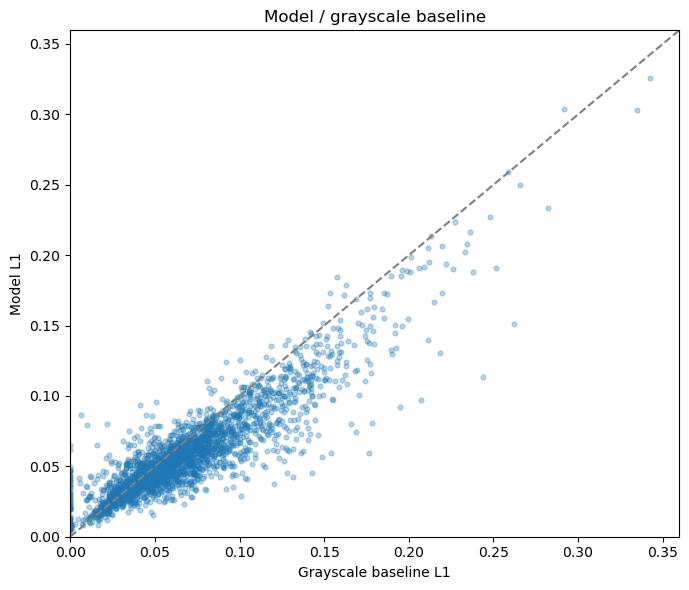

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(gray_losses, losses, alpha=0.3, s=12)

limit = max(max(gray_losses), max(losses)) * 1.05
ax.plot([0, limit], [0, limit], linestyle="--", color="gray", label="Equal L1")
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_xlabel("Grayscale baseline L1")
ax.set_ylabel("Model L1")
ax.set_title("Model / grayscale baseline")
plt.tight_layout()
plt.show()

При маленьких значениях ошибки grayscale довольно часто оказываются лучше. Это связано с тем что если изобржаене черное белое но обычно данным объектам  свойственны какие то оттенки то модель может ошибочно хоть и тускло но начать их красить и мы получим ошибку

## 6. Conclusions

По сохранённым примерам из раздела 4 видно следующее:

- **Low L1:** в подборке встречаются преимущественно малонасыщенные сцены. Поэтому небольшая L1 не всегда означает успешное восстановление выразительных цветов.
- **Typical L1:** модель восстанавливает некоторые естественные оттенки объектов, но часто делает цветовую палитру приглушённой.
- **High L1:** особенно заметны ошибки на насыщенной зелени, красных цветах, фиолетовом сценическом освещении и тёплых оранжевых сценах. Предсказания нередко смещаются в коричнево-серые тона.